# 05. Análisis de preprocesamiento e iluminación

Clasificación de defectos superficiales de palta Hass: PICADURA y RUSSET  
Maestría en Inteligencia Artificial — Trabajo de Investigación  
Corte: 25 de octubre de 2026

Este cuaderno reúne las pruebas realizadas después del corte `04_Analisis_Errores_ResNet50.ipynb`.

Su propósito es documentar el análisis visual de los errores de FT_D1 y comprobar cómo afecta un ajuste de brillo y contraste a sus predicciones. Contiene figuras y resultados integrados para lectura sin ejecución. Las celdas de Python al final son opcionales y utilizan los archivos CSV ya guardados en el proyecto.

No entrena modelos, no escribe sobre el dataset y no utiliza el conjunto `test`.


## 1. Punto de partida

Se completaron los seis experimentos anteriores. FT_D1 continúa siendo el mejor candidato provisional según el Macro-F1 observado en `validation`.

| Experimento | Característica principal | Accuracy | Macro-F1 | Recall RUSSET |
|:--|:--|--:|--:|--:|
| B0 | Extractor ResNet50 congelado, 256 × 512 | 84.25 % | 0.6604 | 33.33 % |
| V1 | Entrada 384 × 768 | 85.83 % | 0.6598 | 28.57 % |
| D1 | 77 copias fotométricas adicionales de RUSSET | 84.25 % | 0.7033 | 47.62 % |
| D2 | 154 copias adicionales de RUSSET | 85.83 % | 0.6944 | 38.10 % |
| FT_B0 | Ajuste parcial de `conv5` a partir de B0 | 86.61 % | 0.7183 | 42.86 % |
| FT_D1 | Ajuste parcial de `conv5` a partir de D1 | **87.40 %** | **0.7524** | **52.38 %** |

Dataset original: 829 TIFF. Se excluyeron lógicamente cuatro archivos con coincidencias exactas entre particiones. Quedaron 572 TIFF para `train`, 127 para `validation` y 126 para `test` reservado. Cada TIFF contiene tres franjas horizontales de cámara y múltiples vistas de la misma palta. No se divide un fruto en muestras independientes.

Las métricas citadas provienen del historial experimental compartido y de las salidas de `validation`; este cuaderno no recalcula esos entrenamientos.


## 2. Problema observado en FT_D1

La matriz de confusión de FT_D1 fue:

| Clase real / Predicción | PICADURA | RUSSET |
|:--|--:|--:|
| PICADURA | 100 | 6 |
| RUSSET | 10 | 11 |

En total, 111 de 127 imágenes se clasificaron correctamente y 16 incorrectamente. Entre los 16 errores, hubo tres RUSSET clasificadas como PICADURA con puntuaciones del modelo superiores al 90 %: aproximadamente 97.76 %, 93.17 % y 90.50 %.

El checkpoint elegido por la menor pérdida de validación fue el de la época 4 (`val_loss = 0.3529`), aunque se entrenó durante ocho épocas. Las curvas mostraron señales de sobreajuste posterior.

Importante: la salida softmax se describe como puntuación del modelo. No equivale necesariamente a una probabilidad calibrada.


## 3. Inspección visual: errores y aciertos de RUSSET

Se compararon tres errores RUSSET→PICADURA de alta puntuación incorrecta con tres aciertos RUSSET. Cada TIFF se mostró completo, en su versión original y con brillo 2.0 + contraste 1.25. Las imágenes mejoradas se generaron únicamente en memoria para inspección.

### Casos mal clasificados


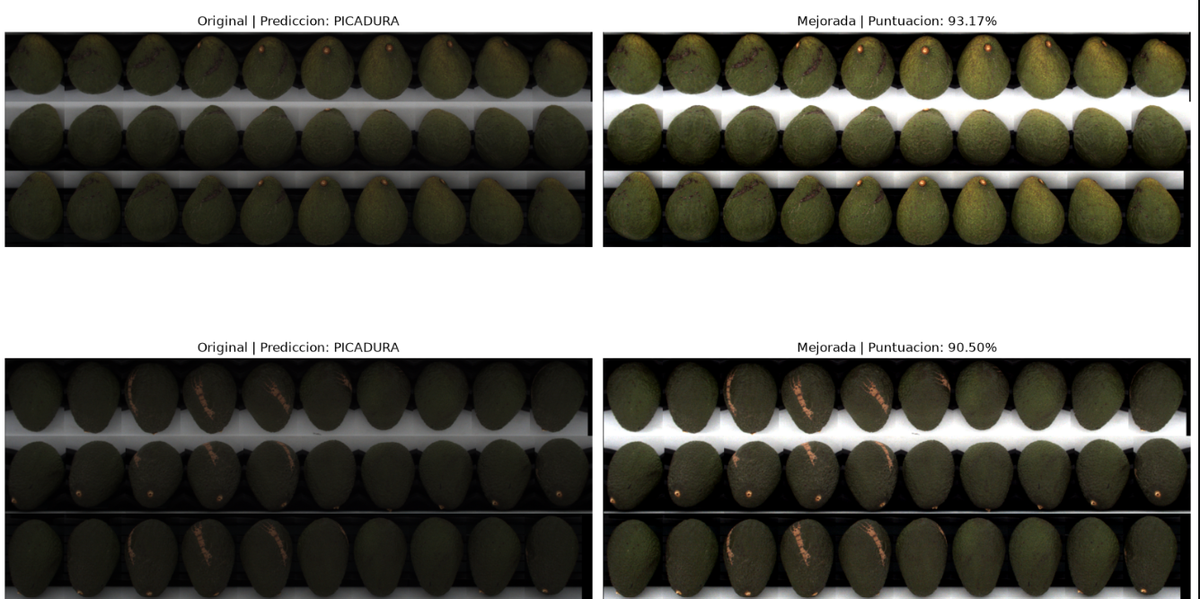

*En las RUSSET confundidas con PICADURA se observan zonas marrones/rojizas de diferente tamaño. En algunos casos las marcas ya eran visibles antes del ajuste; la iluminación no explica todos los errores.*


### Casos correctamente clasificados


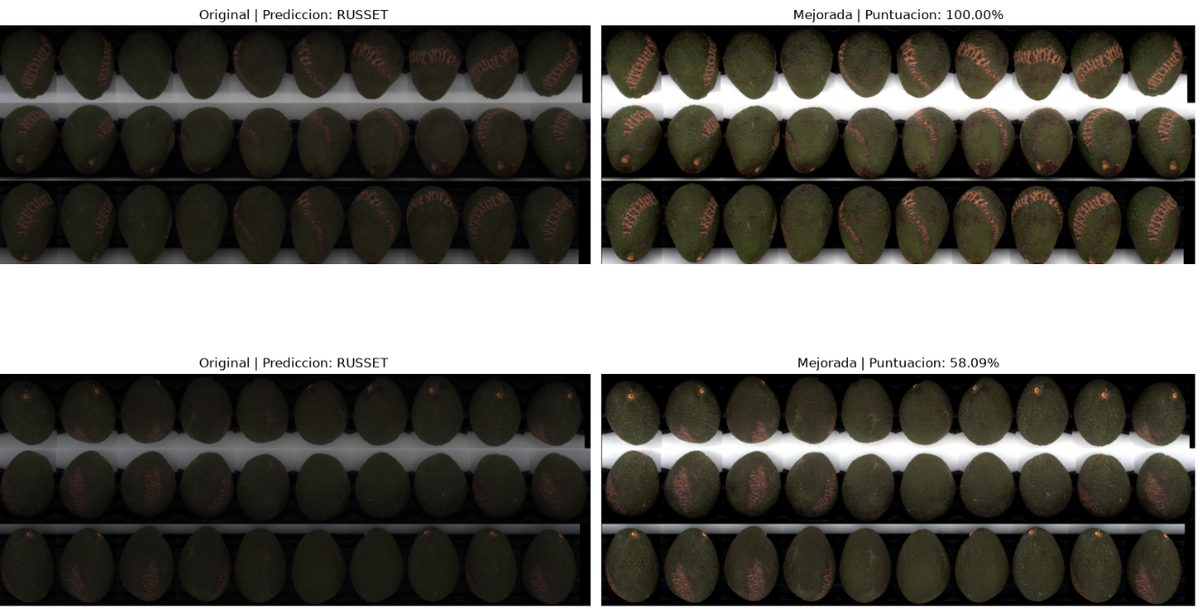

*Los aciertos muestran marcas superficiales de distintos patrones e intensidades. Hay casos muy evidentes y otros de señales más sutiles; las etiquetas provienen del dataset y no de una nueva inspección especializada.*


## 4. Efecto de la resolución: observación descriptiva

Al reducir toda la composición multivista al tamaño 256 × 512, los detalles más finos son menos fáciles de distinguir a simple vista, mientras que las marcas grandes siguen siendo reconocibles. Las dos versiones están ampliadas en pantalla: esta observación es cualitativa.

La prueba V1 de mayor resolución tampoco produjo una mejora del Macro-F1. No puede atribuirse el error exclusivamente a la resolución.


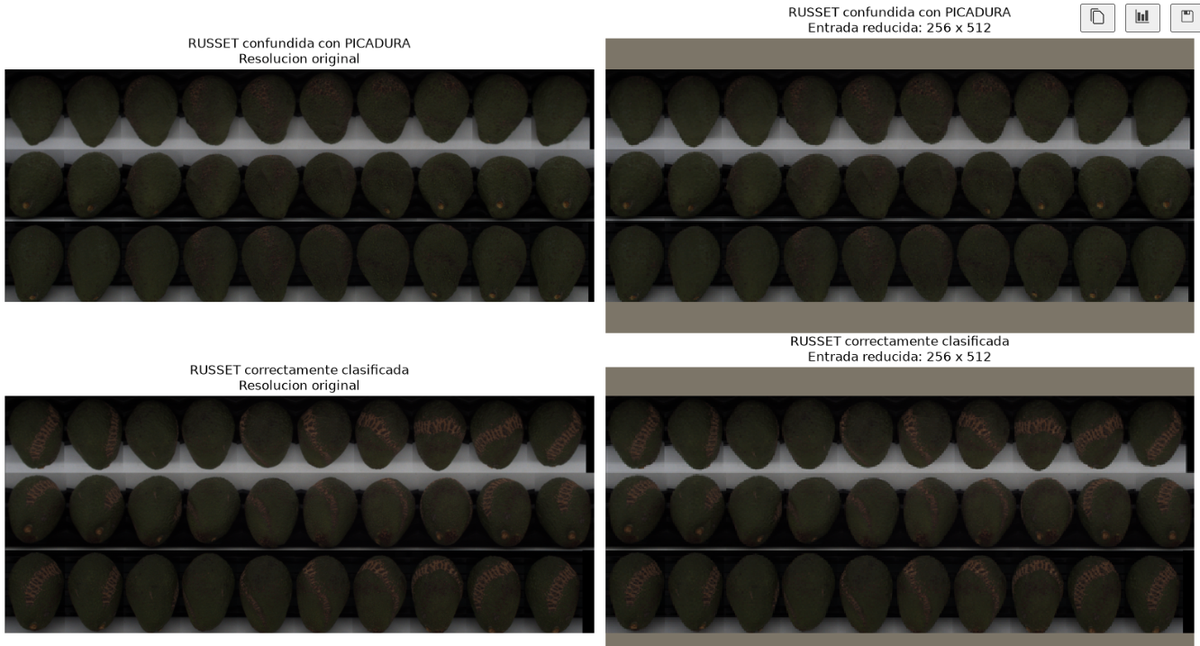

*Comparación visual de una RUSSET errada y una acertada, original frente a reducción con relleno. No corresponde a una nueva evaluación del modelo.*


## 5. Prueba de iluminación sobre seis imágenes

Se aplicaron brillo ×2.0 y contraste ×1.25 a tres errores y tres aciertos de RUSSET, utilizando el mismo modelo FT_D1 ya entrenado. Se verificó que la salida sobre las imágenes originales coincidía exactamente con el archivo guardado (diferencia máxima observada: 0.0).

| Caso | Puntuación RUSSET original | Puntuación RUSSET ajustada | Clasificación después |
|:--|--:|--:|:--|
| Error 1 | 0.0224 | 0.0961 | PICADURA (sigue incorrecta) |
| Error 2 | 0.0683 | 0.0278 | PICADURA (sigue incorrecta) |
| Error 3 | 0.0950 | 0.2842 | PICADURA (sigue incorrecta) |
| Acierto 1 | 0.7048 | 0.9734 | RUSSET (sigue correcta) |
| Acierto 2 | 1.0000 | 1.0000 | RUSSET (sigue correcta) |
| Acierto 3 | 0.5809 | 0.8368 | RUSSET (sigue correcta) |

El ajuste cambió varias puntuaciones, pero ninguna de estas seis etiquetas predichas. Esto motivó una comparación más amplia sobre las 127 imágenes elegibles de `validation`.


## 6. Prueba sobre las 127 imágenes de validación

Sin reentrenar FT_D1, se clasificaron de nuevo las 127 imágenes, esta vez aplicando brillo ×2.0 y contraste ×1.25 antes de la entrada al modelo. No se alteraron los TIFF ni los pesos del checkpoint.

| Métrica | Entrada original | Entrada ajustada | Diferencia |
|:--|--:|--:|--:|
| Accuracy | **87.40 %** | 85.83 % | −1.57 puntos porcentuales |
| Macro-F1 | **0.7524** | 0.7433 | −0.0091 |
| Recall RUSSET | 52.38 % | **57.14 %** | +4.76 puntos porcentuales |
| RUSSET detectadas | 11/21 | 12/21 | +1 |

Se modificaron diez etiquetas predichas: cuatro errores originales fueron corregidos, pero aparecieron seis errores nuevos. La diferencia neta fue de dos clasificaciones correctas menos.

Matriz original (filas reales: PICADURA, RUSSET): `[[100, 6], [10, 11]]`.

Matriz ajustada: `[[97, 9], [9, 12]]`.

El ajuste favoreció ligeramente la detección de RUSSET pero redujo el desempeño equilibrado global. Por tanto, el procesamiento original sigue siendo la referencia provisional.


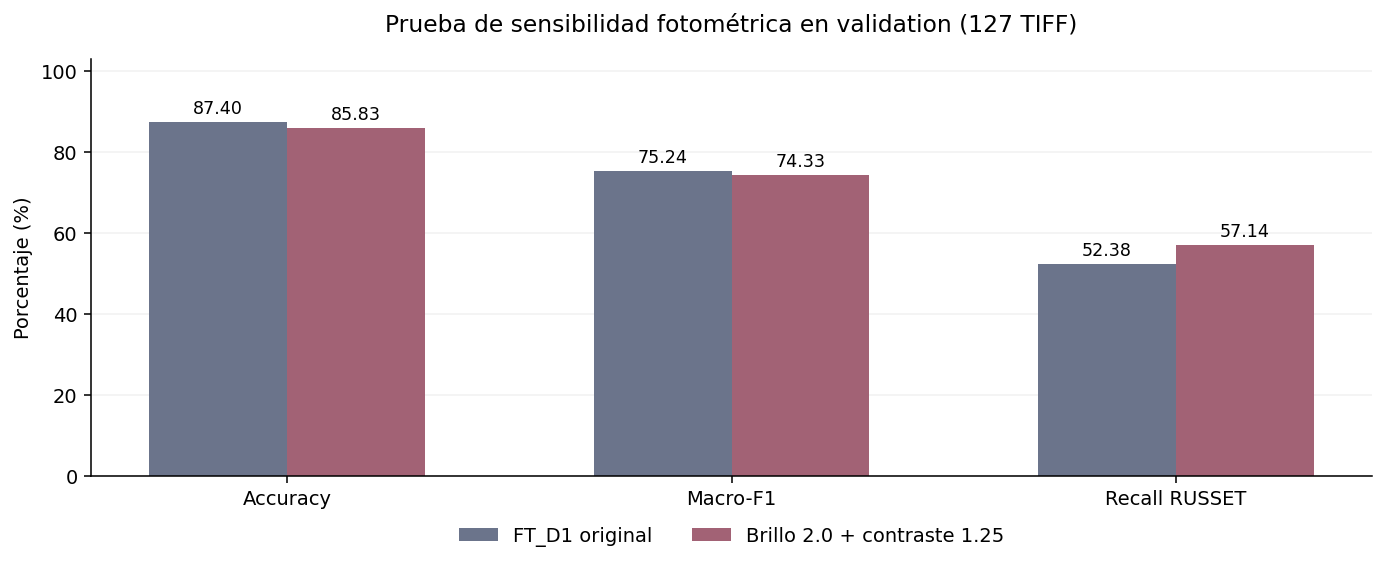

## 7. Comparación con el aumento fotométrico usado en D1

D1 ya incluía 77 copias adicionales de RUSSET, con transformaciones mucho más moderadas que la prueba de iluminación descrita arriba.

| Factor | Mínimo observado | Media observada | Máximo observado |
|:--|--:|--:|--:|
| Brillo | 0.9269 | 0.9983 | 1.0800 |
| Contraste | 0.9008 | 0.9936 | 1.0940 |

D1 aplicó esos cambios únicamente en copias de imágenes RUSSET de `train` y mantuvo fijos los TIFF de `validation`. En cambio, la prueba exploratoria reciente aplicó brillo 2.0 y contraste 1.25 exclusivamente durante la inferencia de `validation`. **No son protocolos equivalentes** ni permiten inferir directamente el efecto de entrenar con ajustes intensos.


## 8. Conclusiones y límites de interpretación

1. El aumento visual de brillo y contraste hizo más evidente parte de la textura superficial, pero la mejora visual para una persona no garantizó una mejor clasificación por ResNet50.
2. En la prueba sobre las 127 imágenes, el recall RUSSET mejoró de 11/21 a 12/21, mientras que accuracy y Macro-F1 disminuyeron.
3. La iluminación y la reducción de resolución son hipótesis plausibles de dificultad, pero hay errores con marcas visibles. No se atribuye una causa única sin análisis adicional.
4. La comparación utilizó un solo conjunto de validación con 21 muestras RUSSET y un único ajuste fotométrico intenso. Los resultados son exploratorios.
5. El conjunto `test` permanece reservado. Tampoco se ha demostrado independencia por lote/sesión de captura, más allá de la eliminación de duplicados exactos.
6. Los TIFF originales, las tres franjas de cámara y todas las vistas del fruto permanecen intactos.

La recomendación actual es mantener **FT_D1 original** como candidato provisional. No reemplazarlo por la versión con brillo aumentado.


## 9. Próximo experimento propuesto (pendiente, no ejecutado)

Diseñar una evaluación controlada de augmentation fotométrica leve durante el **entrenamiento**, no solamente durante la inferencia. Mantener constantes la partición, las exclusiones, la arquitectura ResNet50, la evaluación en validation y la política de checkpoint.

- Establecer previamente rangos moderados de brillo y contraste para evitar sobreexposición.
- Comparar una nueva variante de entrenamiento con el protocolo FT_D1 sin usar `test` para decidir hiperparámetros.
- Aplicar cambios únicamente a muestras de `train`, conservando las vistas de cada TIFF y su orden horizontal.
- Registrar cantidad de muestras efectivas, balance de clases, semillas, pesos de clase, coste de GPU y curvas de validación.
- Analizar si mejora el Macro-F1 y el recall RUSSET sin incrementar excesivamente los falsos positivos en PICADURA.
- Si es posible, repetir el protocolo con distintas semillas y verificar trazabilidad por fruto/lote antes de conclusiones generalizables.

Este corte no contiene un nuevo entrenamiento ni resultados de esta variante; queda documentada como trabajo futuro.


---

# Apéndice. Verificación opcional a partir de archivos del proyecto

Las tablas y capturas anteriores están guardadas dentro de este notebook, por lo que puedes leerlo en otra computadora sin ejecutar nada.

Si lo colocas dentro de `1. fuentes` del repositorio `PROYECTO_TI_2`, las siguientes celdas permiten **recalcular** el resumen leyendo los CSV originales. No escriben archivos ni ejecutan entrenamiento. Para reproducir las visualizaciones de TIFF se necesita acceso a la carpeta `DATASET_PALTA`, situada fuera del repositorio.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

RAIZ = next(
    (ruta for ruta in (Path.cwd(), *Path.cwd().parents)
     if (ruta / "7. resultados" / "entrenamiento").is_dir()),
    None
)
if RAIZ is None:
    raise FileNotFoundError("Abra este notebook desde la carpeta PROYECTO_TI_2.")

CARPETA_FT = RAIZ / "7. resultados" / "entrenamiento" / "FT_D1_s42_03"
CARPETA_D1 = RAIZ / "7. resultados" / "entrenamiento" / "D1_s42_03"
DATASET = RAIZ.parent / "DATASET_PALTA"

for nombre, ruta in {
    "Predicciones FT_D1": CARPETA_FT / "predicciones_validation.csv",
    "Errores FT_D1": CARPETA_FT / "analisis_errores_validation.csv",
    "Sensibilidad a iluminación": CARPETA_FT / "sensibilidad_brillo_contraste_validation.csv",
    "Copias RUSSET de D1": CARPETA_D1 / "copias_russet_train.csv",
    "Dataset TIFF": DATASET,
}.items():
    print(f"{nombre}: {'Disponible' if ruta.exists() else 'No encontrado'}")

print("Raíz del proyecto:", RAIZ)


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

archivo_pred = CARPETA_FT / "predicciones_validation.csv"
if not archivo_pred.is_file():
    raise FileNotFoundError(f"Falta el archivo original: {archivo_pred}")

pred = pd.read_csv(archivo_pred)
requeridas = {"archivo", "clase", "prediccion", "probabilidad_PICADURA", "probabilidad_RUSSET"}
if not requeridas.issubset(pred.columns):
    raise ValueError("Faltan columnas en predicciones_validation.csv.")

reales = pred["clase"].to_numpy()
originales = pred["prediccion"].to_numpy()

print("Imágenes elegibles evaluadas:", len(pred))
print("Matriz FT_D1 original:")
print(confusion_matrix(reales, originales, labels=["PICADURA", "RUSSET"]))
print("Accuracy:", round(accuracy_score(reales, originales), 4))
print("Macro-F1:", round(f1_score(reales, originales, average="macro"), 4))
print("Recall RUSSET:", round(recall_score(reales, originales, pos_label="RUSSET"), 4))

errores = pred[pred["clase"] != pred["prediccion"]].copy()
errores["p_prediccion"] = np.where(
    errores["prediccion"].eq("PICADURA"),
    errores["probabilidad_PICADURA"],
    errores["probabilidad_RUSSET"]
)
print("Errores:", len(errores))
print("Errores con puntuación >=90%:", int((errores["p_prediccion"] >= 0.9).sum()))
display(errores.sort_values("p_prediccion", ascending=False).head(8))


In [ ]:
archivo_sensibilidad = CARPETA_FT / "sensibilidad_brillo_contraste_validation.csv"
if archivo_sensibilidad.is_file():
    sens = pd.read_csv(archivo_sensibilidad)
    obligatorias = {"archivo", "clase", "prediccion", "prediccion_ajustada"}
    if not obligatorias.issubset(sens.columns):
        raise ValueError("El CSV de sensibilidad no contiene las columnas esperadas.")
    if len(sens) != len(pred) or set(sens["archivo"]) != set(pred["archivo"]):
        raise ValueError("La tabla de sensibilidad no coincide con los archivos de validation.")
    sens = pred[["archivo", "clase", "prediccion"]].merge(
        sens[["archivo", "prediccion_ajustada"]], on="archivo", validate="one_to_one"
    )
    y = sens["clase"]
    p0 = sens["prediccion"]
    p1 = sens["prediccion_ajustada"]
    resumen = pd.DataFrame([
        {"condicion": "Original", "accuracy": accuracy_score(y,p0),
         "macro_f1": f1_score(y,p0,average="macro"),
         "recall_russet": recall_score(y,p0,pos_label="RUSSET")},
        {"condicion": "Brillo 2.0 y contraste 1.25", "accuracy": accuracy_score(y,p1),
         "macro_f1": f1_score(y,p1,average="macro"),
         "recall_russet": recall_score(y,p1,pos_label="RUSSET")},
    ])
    display(resumen.round(4))
    print("Predicciones modificadas:", int((p0 != p1).sum()))
    print("Errores corregidos:", int(((p0 != y)&(p1 == y)).sum()))
    print("Errores nuevos:", int(((p0 == y)&(p1 != y)).sum()))
    print("Matriz original:\n", confusion_matrix(y,p0,labels=["PICADURA","RUSSET"]))
    print("Matriz ajustada:\n", confusion_matrix(y,p1,labels=["PICADURA","RUSSET"]))
else:
    print("No se encontró el CSV de sensibilidad; el resumen del corte sigue disponible arriba.")


In [ ]:
archivo_copias = CARPETA_D1 / "copias_russet_train.csv"
if archivo_copias.is_file():
    copias = pd.read_csv(archivo_copias)
    print("Copias adicionales de RUSSET:", len(copias))
    display(copias[["brillo", "contraste"]].agg(["min", "mean", "max"]).round(4))
else:
    print("No se encontró el plan D1 en la ruta esperada.")


## Visualización opcional de las seis paltas

Este código utiliza exclusivamente `validation` y muestra las composiciones completas en original y con iluminación ajustada. La salida depende de que el dataset esté presente. Las imágenes originales siguen intactas.


In [ ]:
from PIL import Image, ImageEnhance
import matplotlib.pyplot as plt

if not DATASET.is_dir():
    print("No se encuentra DATASET_PALTA. Se conservan las figuras del informe de arriba.")
else:
    russet = pred[pred["clase"] == "RUSSET"]
    incorrectas = russet[russet["prediccion"] == "PICADURA"].sort_values(
        "probabilidad_PICADURA", ascending=False
    ).head(3)
    correctas = russet[russet["prediccion"] == "RUSSET"].sample(
        n=3, random_state=42
    )
    casos = pd.concat([incorrectas, correctas], ignore_index=True)
    fig, ejes = plt.subplots(len(casos), 2, figsize=(14, 3.1*len(casos)), squeeze=False)
    for i, fila in casos.iterrows():
        ruta = DATASET / fila["archivo"]
        if not ruta.is_file():
            raise FileNotFoundError(ruta)
        with Image.open(ruta) as entrada:
            imagen = entrada.convert("RGB")
            imagen.thumbnail((1300, 750))
            original = imagen.copy()
        iluminada = ImageEnhance.Contrast(
            ImageEnhance.Brightness(original).enhance(2.0)
        ).enhance(1.25)
        for j, muestra in enumerate((original, iluminada)):
            ejes[i,j].imshow(muestra)
            ejes[i,j].axis('off')
            ejes[i,j].set_title(
                f"{fila['clase']} → {fila['prediccion']} | " +
                ("original" if j==0 else "brillo/contraste")
            )
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## Archivos de evidencia en el proyecto

- `7. resultados/entrenamiento/FT_D1_s42_03/predicciones_validation.csv`
- `7. resultados/entrenamiento/FT_D1_s42_03/analisis_errores_validation.csv`
- `7. resultados/entrenamiento/FT_D1_s42_03/sensibilidad_brillo_contraste_validation.csv`
- `7. resultados/entrenamiento/D1_s42_03/copias_russet_train.csv`
- `6. entrenamiento/resnet50.ipynb` (entrenamiento y fine-tuning originales)

El objetivo de este cuaderno es que el análisis exploratorio permanezca separado del notebook principal de entrenamiento. Ninguna celda ejecuta `fit`, actualiza pesos o evalúa `test`.
